In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex


#import csv

import numpy as np
from numpy import diff

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import itertools

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Derive_Smooth_And_Find_Peaks
from scientific_utils.battery.plotting import Matplotlib_Data_Smoothed_Residuals
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.statistics.plotting import Matplotlib_FFT_Spectra_Comparison
from scientific_utils.statistics.plotting import Matplotlib_Histogram_Residuals
from scientific_utils.statistics.plotting import Matplotlib_QQ_Plot
from scientific_utils.statistics.plotting import Matplotlib_Residuals_Vs_Value

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########
########## Open the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge = pickle.load(f)
    
    

########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = [0.10, 0.33, 1.00]


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 3 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
####################### Definition of Function #######################

In [9]:
#list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
#y_values_column_name_first = 'dQ/dV / mAh/V'
#y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
#rate_to_save = 2
#additional_name = 'charge'
#
#qq_plot(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name)

In [10]:
##################################################################################################################

In [11]:
####################### CHARGING CURVES #######################

In [12]:
# Deleting unneccesary Data
#list_of_dataframes = list_of_dataframes_of_CP_charge_equidistant

#list_of_dataframes_of_CP_charge_equidistant = DeleteListEntries(list_of_dataframes)

In [13]:
# defining the arguments for the function
list_of_dataframes = list_of_dataframes_of_CP_charge
x_values_column_name = '<Ewe>/V'
y_values_column_name = 'Q charge/mA.h'
percent_of_points_used_for_smoothing = [0.025, 0.05, 0.08]
prominence_min_max_for_peakfind = [(0.0005, 8.0), (0.0005, 8.0), (0.0005, 8.0)]
percent_of_points_used_for_peakfind = [0.02, 0.03, 0.10]
positv_or_negativ_peak = 1
dYdX_column_name_new = 'dQ/dV / mAh/V'

# application of the Function for derive and smoothed raw data: curves, peaks per curve and all peaks in one dataframe
list_of_dataframes_of_dQdV_CP_charge_equidistant, list_of_dataframes_of_dQdV_CP_charge_peaks, dataframe_of_dQdV_CP_charge_peaks = Derive_Smooth_And_Find_Peaks(list_of_dataframes, x_values_column_name, y_values_column_name, percent_of_points_used_for_smoothing, prominence_min_max_for_peakfind, percent_of_points_used_for_peakfind, positv_or_negativ_peak, dYdX_column_name_new, list_of_labels=list_RateTest_labels) # one call returns all three results

print(list_of_dataframes_of_dQdV_CP_charge_peaks)

[[   Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          7.375571                    3.027431   0.1,    Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          7.232055                    3.058408   0.1,    Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          5.007824                    3.182724   0.1,    Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          2.360134                    3.392479   0.1,    Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          3.336614                    3.597561   0.1], [   Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                           3.68913                    3.169829  0.33,    Peak Savgol-Filter dQ/dV / mAh/V  Peak Savgol-Filter <Ewe>/V  Rate
0                          1.946414                    3.413128  0.33,    Peak S

In [14]:
################ FEHLER!!!!!! ################
#Label WRONG -> check the definition of the plotting function!!!!!!

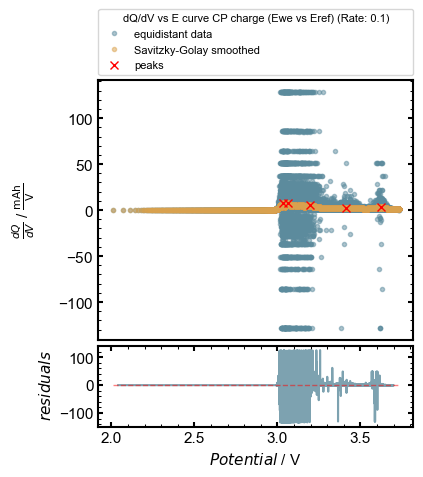

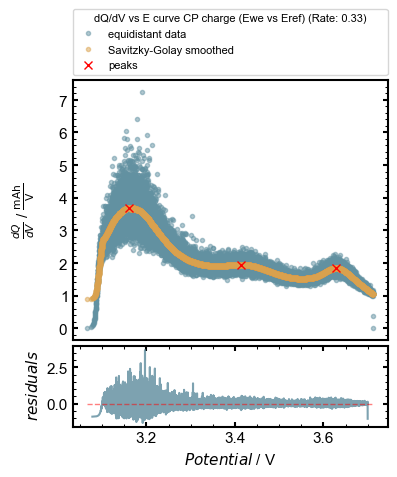

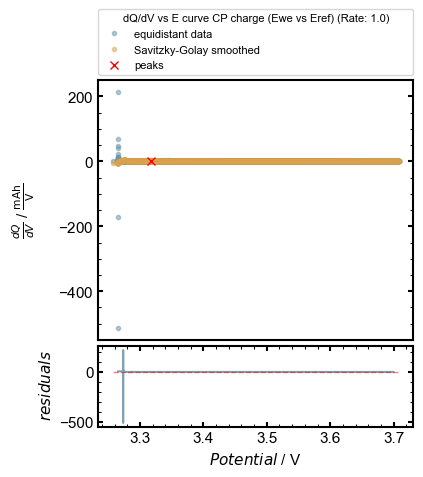

In [15]:
# Plotting of the raw data and smoothed data and the residuals
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
x_values_column_name = '<Ewe>/V'
y_values_column_name = 'dQ/dV / mAh/V'
y_values_smoothed_column_name = 'Savgol-Filter dQ/dV / mAh/V'
list_of_dataframes_peaks = list_of_dataframes_of_dQdV_CP_charge_peaks
x_peak_values_column_name = 'Peak Savgol-Filter <Ewe>/V'
y_peak_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1
additional_name = 'charge'
legend_title = 'dQ/dV vs E curve CP charge (Ewe vs Eref)'

Matplotlib_Data_Smoothed_Residuals(list_of_dataframes, x_values_column_name, y_values_column_name, y_values_smoothed_column_name, list_of_dataframes_peaks, x_peak_values_column_name, y_peak_values_column_name, rate_to_save, additional_name, legend_title, list_of_labels=list_RateTest_labels, set_axis_limits=False)

In [16]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
x_values_column_name = 'Savgol-Filter dQ/dV / mAh/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1 
additional_name = 'charge'
legend_title = 'residuals vs dQ/dV curve CP charge (Ewe vs Eref)'

#ResidualsVSValue(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name,legend_title)

In [17]:
# Plotting the fourier transform of the curve

list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
x_values_column_name = '<Ewe>/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1
additional_name = 'charge'
legend_title = 'Fourier Transform of the charge dQdV vs Potential Graph'
y_ax_label = r' $Amplitude$ / V'
x_ax_label = r' $Potential$ $(Fourier Space)$ / $\frac{\mathsf{V}}{\mathsf{Hz}}$' 

#FFTSpectraComparison(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name,legend_title, y_ax_label, x_ax_label)


In [18]:
# Plotting histogram of the residuals
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1
additional_name = 'charge'
legend_title = "Histogram of normalized residuals charge"

#Histogram(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name, legend_title)

In [19]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1
additional_name = 'charge'

#qq_plot(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name)

In [20]:
########################## DISCHARGE CURVE ###################

In [21]:
#list_of_dataframes = list_of_dataframes_of_CP_discharge_equidistant

#list_of_dataframes_of_CP_discharge_equidistant = DeleteListEntries(list_of_dataframes)

In [22]:
# defining the arguments for the function
list_of_dataframes = list_of_dataframes_of_CP_discharge
x_values_column_name = '<Ewe>/V'
y_values_column_name = 'Q discharge/mA.h'
percent_of_points_used_for_smoothing = [0.04, 0.05, 0.08]
prominence_min_max_for_peakfind = [(0.0005, 8.0), (0.0005, 8.0), (0.0005, 8.0)]
percent_of_points_used_for_peakfind = [0.01, 0.02, 0.10]
positv_or_negativ_peak = -1
dYdX_column_name_new = 'dQ/dV / mAh/V'

# application of the Function for derive and smoothed raw data: curves, peaks per curve and all peaks in one dataframe
list_of_dataframes_of_dQdV_CP_discharge_equidistant, list_of_dataframes_of_dQdV_CP_discharge_peaks, dataframe_of_dQdV_CP_discharge_peaks = Derive_Smooth_And_Find_Peaks(list_of_dataframes, x_values_column_name, y_values_column_name, percent_of_points_used_for_smoothing, prominence_min_max_for_peakfind, percent_of_points_used_for_peakfind, positv_or_negativ_peak, dYdX_column_name_new, list_of_labels=list_RateTest_labels) # one call returns all three results

#print(list_of_dataframes_of_dQdV_CP_charge_peaks_cycling)

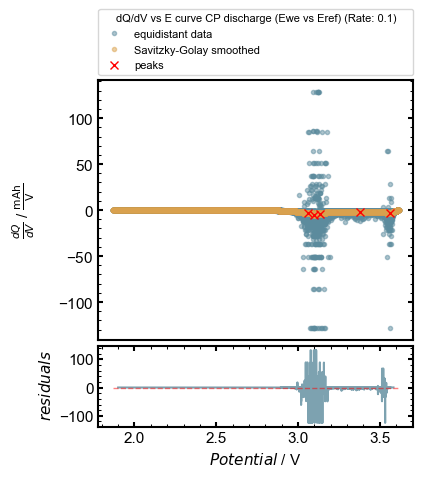

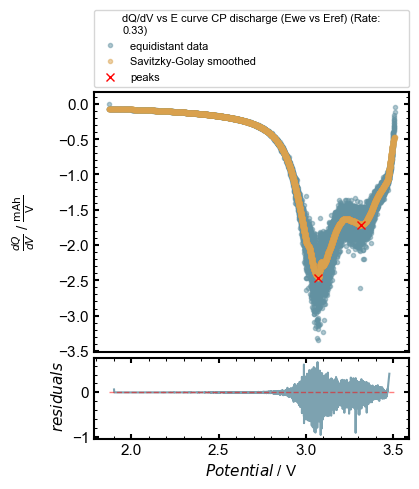

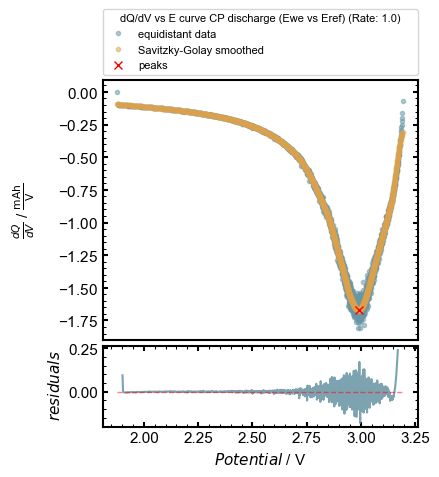

In [23]:
# Plotting of the raw data and smoothed data and the residuals
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant
x_values_column_name = '<Ewe>/V'
y_values_column_name = 'dQ/dV / mAh/V'
y_values_smoothed_column_name = 'Savgol-Filter dQ/dV / mAh/V'
list_of_dataframes_peaks = list_of_dataframes_of_dQdV_CP_discharge_peaks
x_peak_values_column_name = 'Peak Savgol-Filter <Ewe>/V'
y_peak_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 3
additional_name = 'discharge'
legend_title = 'dQ/dV vs E curve CP discharge (Ewe vs Eref)'

Matplotlib_Data_Smoothed_Residuals(list_of_dataframes, x_values_column_name, y_values_column_name, y_values_smoothed_column_name, list_of_dataframes_peaks, x_peak_values_column_name, y_peak_values_column_name, rate_to_save, additional_name, legend_title, list_of_labels=list_RateTest_labels, set_axis_limits=False)

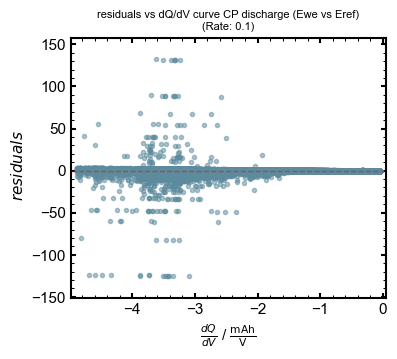

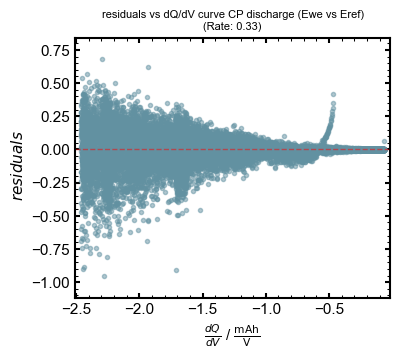

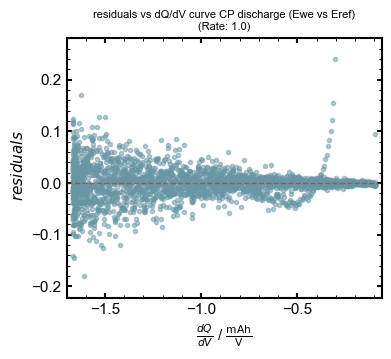

In [24]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant
x_values_column_name = 'Savgol-Filter dQ/dV / mAh/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = 1
additional_name = 'discharge'
legend_title = 'residuals vs dQ/dV curve CP discharge (Ewe vs Eref)'

Matplotlib_Residuals_Vs_Value(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name,legend_title, list_of_labels=list_RateTest_labels)

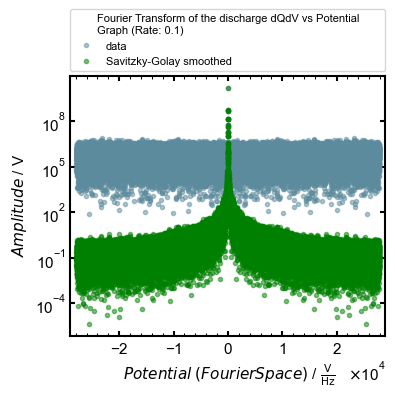

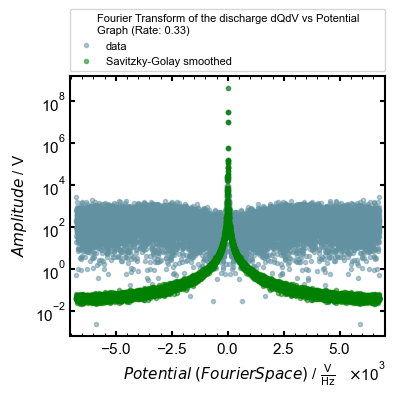

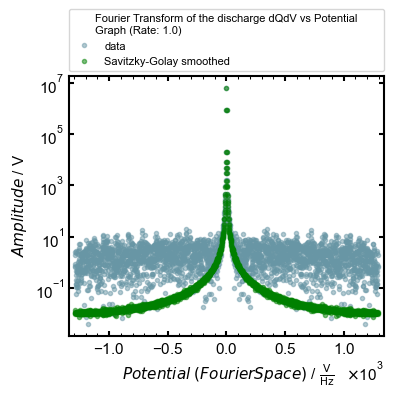

In [25]:
# Plotting the fourier transform of the curve

list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant
x_values_column_name = '<Ewe>/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = -1
additional_name = 'discharge'
legend_title = 'Fourier Transform of the discharge dQdV vs Potential Graph'
y_ax_label = r' $Amplitude$ / V'
x_ax_label = r' $Potential$ $(Fourier Space)$ / $\frac{\mathsf{V}}{\mathsf{Hz}}$' 

Matplotlib_FFT_Spectra_Comparison(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name,legend_title, y_ax_label, x_ax_label, list_of_labels=list_RateTest_labels)


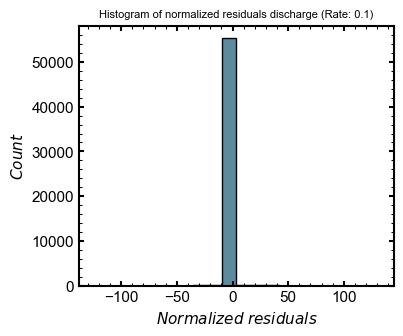

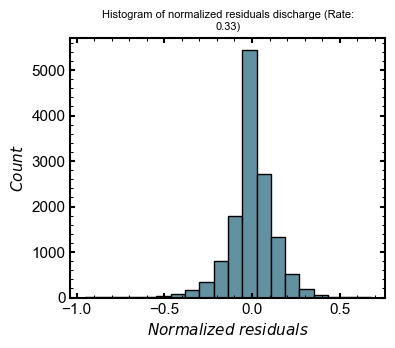

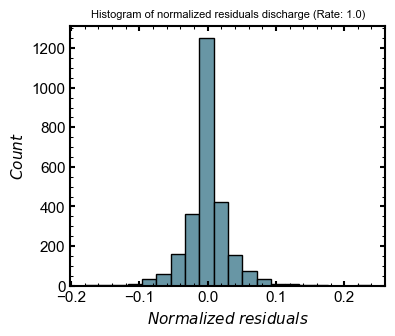

In [26]:
# Plotting histogram of the residuals
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = -1
additional_name = 'discharge'
legend_title = "Histogram of normalized residuals discharge"

Matplotlib_Histogram_Residuals(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name, legend_title, list_of_labels=list_RateTest_labels)

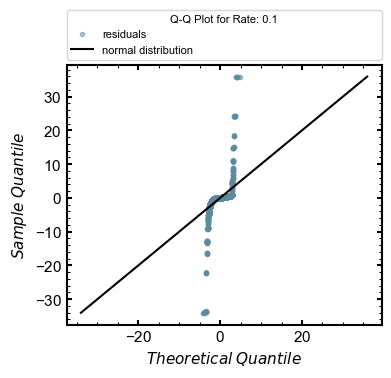

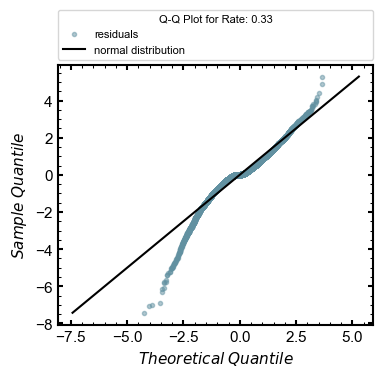

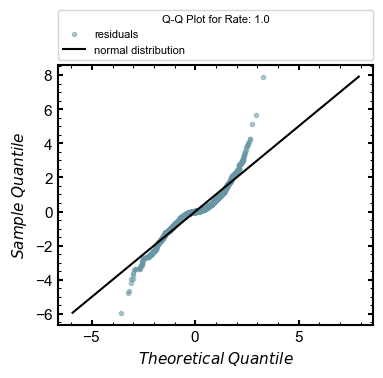

In [27]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
rate_to_save = -1
additional_name = 'discharge'

Matplotlib_QQ_Plot(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, rate_to_save, additional_name, list_of_labels=list_RateTest_labels)

In [28]:
#print(list_of_dataframes_of_dQdV_CP_charge_peaks)

In [29]:
#print(list_of_dataframes_of_dQdV_CP_discharge_peaks)

In [30]:
#print(dataframe_of_dQdV_CP_charge_peaks)

In [31]:
#print(dataframe_of_dQdV_CP_discharge_peaks)

In [32]:
######### Saving of the extracted data ###########

In [33]:
########## Save the data as .pkl ##########

##### Charge Curves peaks
with open('../data/Batt15/processed/dataframe_of_dQdV_CP_charge_peaks_from_raw_data.pkl', 'wb') as f:
    pickle.dump(dataframe_of_dQdV_CP_charge_peaks, f)

##### Discharge Curves peaks
with open('../data/Batt15/processed/dataframe_of_dQdV_CP_discharge_peaks_from_raw_data.pkl', 'wb') as f:
    pickle.dump(dataframe_of_dQdV_CP_discharge_peaks, f)  